In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# High level imports
from wrtds_py import WRTDS, WRTDSK


# Data
Import the data from the reference `data.csv` in the `tests` folder. The data are nitrate concentrations in mg/L for the Grand River near the neighborhood of Doon in Kitchener, Ontario, Canada. The nitrate data are from Station ID 803745 from DataStream Canada and it has been co-located with the HyDAT gauge 02GA048 to include a record of streamflow in m3/s.

Here we read the data and separate the columns into the DataFrames `df_wq` and `df_q` for the nitrate concentrations and streamflow, respectively.

In [2]:
df = pd.read_csv('../tests/data.csv', index_col=0, parse_dates=True)

df_q = df[['Q']].copy()
df_wq = df.dropna(subset=['Conc', 'Uncen'])
df_wq['Q'] = np.nan
for date in df_wq.index:
    df_wq.loc[date, 'Q'] = df_q.loc[date, 'Q']

# Re-cast the censorship flag to integer
df_wq['Uncen'] = df_wq['Uncen'].astype(int)

# Prepare the data summary table
num_wq, num_q = df_wq.shape[0], df_q.shape[0]
min_date_wq, max_date_wq = df_wq.index.min().strftime('%d-%m-%Y'), df_wq.index.max().strftime('%d-%m-%Y')
min_date_q, max_date_q = df_q.index.min().strftime('%d-%m-%Y'), df_q.index.max().strftime('%d-%m-%Y')

# Print summary table
print(f"{'Data':<15} | {'Start Date':<12} | {'End Date':<12} | {'Num Records':<12}")
print(f"{'-'*15} | {'-'*12} | {'-'*12} | {'-'*12}")
print(f"{'Water Quality':<15} | {min_date_wq:<12} | {max_date_wq:<12} | {num_wq:<12}")
print(f"{'Streamflow':<15} | {min_date_q:<12} | {max_date_q:<12} | {num_q:<12}")

Data            | Start Date   | End Date     | Num Records 
--------------- | ------------ | ------------ | ------------
Water Quality   | 23-03-2007   | 03-12-2016   | 75          
Streamflow      | 23-05-2006   | 31-12-2024   | 6798        


In [3]:
df_q.head()

,Q
Date,
2006-05-23,20.0
2006-05-24,17.5
2006-05-25,14.8
2006-05-26,14.6
2006-05-27,14.0


# Models

## WRTDS

We first instantiate the base WRTDS model with the default parameters and fit it to the data. The model is then used to predict the nitrate concentrations for the `df_wq` DataFrame to calculate the error (as `RMSE`) between the observed and predicted values. Then the model is used to predict the nitrate concentrations for the entire streamflow record in `df_q`.

In [4]:
model = WRTDS()
model = model.fit(df_wq, df_q, verbose=True)

Fitting WRTDS: 100%|##########| 4186/4186 [00:00<00:00, 4393.91it/s]
/Users/manuel/Projects/wrtds-py/src/wrtds_py/models/classic.py:96: UserWarning: Adaptive window expansion triggered for 4186 nodes.
  warnings.warn(f"Adaptive window expansion triggered for {expansion_warnings} nodes.")


In [5]:
y_hat_wq = model.predict(df_wq)
rmse = np.sqrt(np.mean((y_hat_wq['ConcHat'] - df_wq['Conc'])**2))
print(f'RMSE = {rmse:.2f} mg/L')

RMSE = 0.71 mg/L


In [6]:
y_hat_q = model.predict(df_q)

Plot the observed and predicted nitrate concentrations

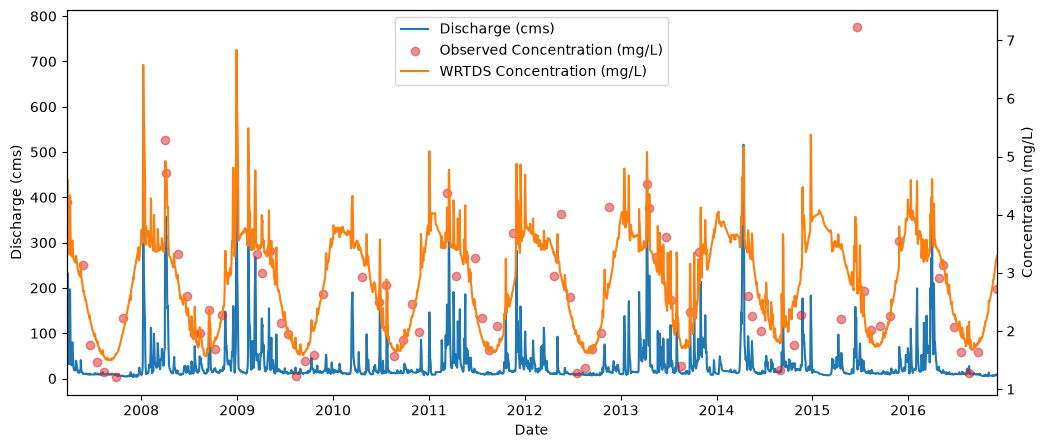

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_hat_q.index, y_hat_q['Q'], label='Discharge (cms)')
ax2 = ax.twinx()
ax2.scatter(df_wq.index, df_wq['Conc'], label='Observed Concentration (mg/L)', color='tab:red', alpha=0.5)
ax2.plot(y_hat_q.index, y_hat_q['ConcHat'], label='WRTDS Concentration (mg/L)', color='tab:orange')
ax.set_xlabel('Date')
ax.set_ylabel('Discharge (cms)')
ax2.set_ylabel('Concentration (mg/L)')
for sub_ax in [ax, ax2]:
    sub_ax.set_xlim(df_wq.index.min(), df_wq.index.max())
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2)
plt.show()

## WRTDS-K
Having a fitted base WRTDS model, we can now instantiate the WRTDS-K model to adjust the predictions made by the base model. The WRTDS-K model is fitted to the residuals of the base model and then used to predict the nitrate concentrations for the entire streamflow record in `df_q`. We again calculate the error (as `RMSE`) by extracting the new predictions in the `df_q_k` DataFrame and comparing them to the observed values in `df_wq`.

In [8]:
modelk = WRTDSK(model, rho=.9, niter=100)
df_q_k = modelk.filter(df_wq, df_q, verbose=True)

Running WRTDS-K: 100%|##########| 100/100 [00:00<00:00, 158.86it/s]


In [9]:
dates_with_obs = df_wq.index

y_obs = df_wq.loc[dates_with_obs, 'Conc']
y_hat_k = df_q_k.loc[dates_with_obs, 'ConcKalman']
rmse_k = np.sqrt(np.mean((y_hat_k - y_obs)**2))
print(f'RMSE after Kalman filtering = {rmse_k:.2f} mg/L')

RMSE after Kalman filtering = 0.00 mg/L


We can plot the observations and predictions again to visualize the improvement in the predictions after applying the Kalman filter.

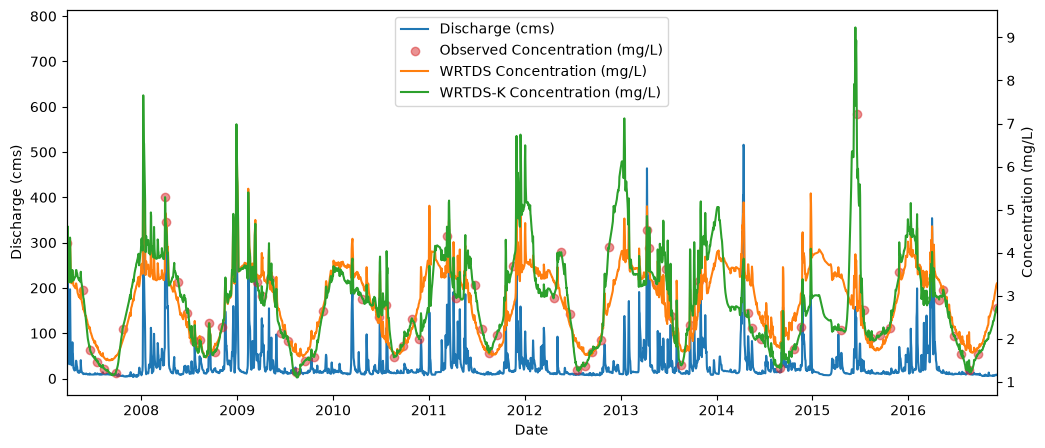

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_hat_q.index, y_hat_q['Q'], label='Discharge (cms)')
ax2 = ax.twinx()
ax2.scatter(df_wq.index, df_wq['Conc'], label='Observed Concentration (mg/L)', color='tab:red', alpha=0.5)
ax2.plot(y_hat_q.index, y_hat_q['ConcHat'], label='WRTDS Concentration (mg/L)', color='tab:orange')
ax2.plot(df_q_k.index, df_q_k['ConcKalman'], label='WRTDS-K Concentration (mg/L)', color='tab:green')
ax.set_xlabel('Date')
ax.set_ylabel('Discharge (cms)')
ax2.set_ylabel('Concentration (mg/L)')
for sub_ax in [ax, ax2]:
    sub_ax.set_xlim(df_wq.index.min(), df_wq.index.max())
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2)
plt.show()

## Prediction Surface

We can also visualize the prediction surface of the WRTDS model directly from the instance of the model. `model.grid_time_` and `model.grid_logq_` are the time and log streamflow grids, and the predictions `ConcHat` are stored in the third dimension of the model's predictive surface. The surface can be visualized using a color mesh plot with the time and streamflow grids as the x and y axes, respectively. The color of the mesh represents the predicted nitrate concentrations.

**NOTE:** this are predictions for every combination of time and streamflow in the grid! Not the actual predictions for the observed streamflow record. The actual predictions for the observed streamflow record are stored in the `y_hat_q` DataFrame.

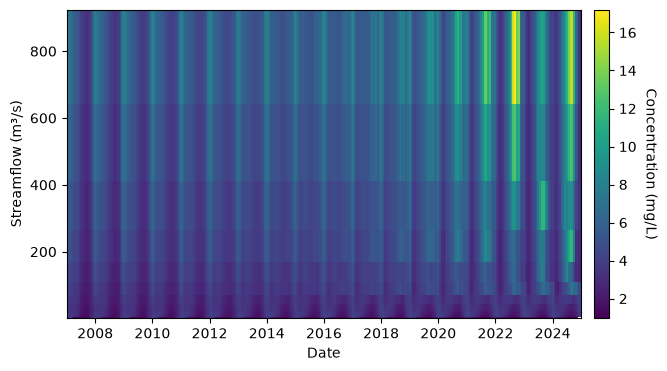

In [11]:
time_grid = np.asarray(model.grid_time_, dtype=np.float64)
logq_grid = np.asarray(model.grid_logq_, dtype=np.float64)
q_vals = np.exp(logq_grid)  # Streamflow in m³/s
conc_surface = np.squeeze(model.surface_[:, :, 2]).copy()

T_mesh, Q_mesh = np.meshgrid(time_grid, q_vals)

fig, ax = plt.subplots(figsize=(8, 4))

mesh = ax.pcolormesh(
    T_mesh,
    Q_mesh,
    conc_surface,
    shading="auto",
    cmap="viridis",
)

cbar = fig.colorbar(mesh, ax=ax, pad=0.02)
cbar.set_label("Concentration (mg/L)", rotation=270, labelpad=15)

ax.set_xlim(2007, 2025)

ax.set_xlabel("Date")
ax.set_ylabel("Streamflow (m³/s)")
plt.show()